# Lab 03: acquire small scientific inputs and explain failures

Automated Workflows in Satellite Image Processing · v1.0 · 15 October 2026

Lab 02 discovered catalogue items and stored one preview. This lab acquires the red
and near-infrared bands needed for NDVI, but stores only a small area of interest.
You design the new database tables completely and then use the resulting archive
to investigate failures.

Use this notebook for predictions, SQL inspection and explanations. Edit
`student_schema.sql` in your editor. Run acquisition and failure cases in a terminal.
The supplied Python is working code, not a new function-repair exercise.

Deliverables: your full schema SQL, your diagnostic SQL, this notebook with evidence
and explanations, and a small final JSON report. Core work: approximately two hours.


## 1. Setup and continuity

Read README.md for installation. From a terminal in this folder, install Rasterio,
NumPy, Matplotlib and Jupyter into your existing environment if needed:

```bash
conda install -c conda-forge "rasterio>=1.4,<2" numpy matplotlib jupyterlab ipykernel
```

We preserve Lab 02's streams, scenes, downloads, runs and stream_scenes tables. You
can copy your database with --from-lab2 on the first init; README.md gives the command.
The default path creates a separate Lab 03 archive and uses captured actual Lab 01
metadata. The original Lab 02 database is never edited by the copy operation.

The fixed example is from June 2025. It is chosen for reproducibility, not presented
as the newest acquisition. Live acquire commands always read remote COG data;
packaged real subsets are used only by offline checks.


In [ ]:
from pathlib import Path
import json
import sqlite3
import subprocess
import sys

PROJECT = Path.cwd().resolve()
assert (PROJECT / 'lab03_cli.py').is_file(), 'Set PROJECT to the extracted lab folder'

def run_checks():
    result = subprocess.run([sys.executable, str(PROJECT / 'check_lab03.py')], cwd=PROJECT, capture_output=True, text=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    print('Exit code:', result.returncode)
    return result.returncode

print('Project:', PROJECT)


Project: E:\github_repos\Automated_Workflows\Labs\Lab03


## 2. Design five complete tables (45–60 minutes)

Read SCHEMA_CONTRACT.md. Write every CREATE TABLE statement yourself in
student_schema.sql. The file initially contains only comments. Required column
names let the supplied service use your schema, but there are no partial table
statements to complete.

Before writing SQL, sketch these relationships and explain the expected cardinality:

| Parent | Child | Question |
|---|---|---|
| scenes | assets | Can one scene have more than one band or metadata revision? |
| assets | subset_requests | Can the same band be stored for two AOIs? |
| subset_requests | download_attempts | Can a request fail and later succeed? |
| runs | download_attempts | Can one invocation attempt more than one band? |
| download_attempts | artifacts | Which attempt first registered these exact bytes? |
| artifacts | artifact_locations | Can a stored file disappear without erasing the artifact's identity? |

Also record each request's latest artifact and each attempt's result artifact.
Those artifacts must belong to the same request, not simply be any existing ID.
The contract explains the composite references needed for that condition.

Which facts belong to current state, and which must remain as history? Do not
make run_id or subset_id unique in the attempts table. Predict what that would
prevent during recovery.


In [2]:
run_checks()


PASS: five complete table definitions and column contract
PASS: primary keys and scene/asset/request/run foreign keys
PASS: AOI identity, uniqueness and allowed states
PASS: attempt outcomes, timestamps and byte counts
PASS: composite relationships prevent cross-AOI artifact references
PASS: real-file verification, missing/corrupt diagnosis and preserved success history
PASS: real B04/B08 grids, AOI masking, scale/offset and pixel cap
PASS: server ignoring Range is refused without reading its body
All checks used actual captured EO data; no live network requests were made.

attempt=attempt-2c43a33f-0e71-4464-9854-74ed1635efb9 code=FILE_MISSING Recorded file is absent: real_red_aoi.tif
attempt=attempt-45a60e06-acd0-4e7b-bc1d-65c5ae038565 code=FILE_CORRUPT Size/hash mismatch for real_red_aoi.tif

Exit code: 0


0

> Write your schema explanation here. Identify two uniqueness constraints and two
foreign key constraints, and give a concrete bad record each would reject. Explain
why an asset+band identity alone is insufficient when the AOI changes.

The `UNIQUE (collection, item_id, asset_key, metadata_sha256)` constraint prevents duplicate asset revisions.

The `UNIQUE (asset_id, aoi_key, recipe_version)` constraint allows one asset to serve different AOIs while preventing duplicate requests.

The foreign keys in `assets` and `subset_requests` ensure that every asset belongs to an existing scene and every request refers to an existing asset.

`asset_id + band` is not enough because the same band can be extracted for different AOIs. The AOI affects the pixel window, shape, transform, mask and output file.

### Schema explanation

The `UNIQUE (collection, item_id, asset_key, metadata_sha256)` constraint prevents duplicate asset revisions.

The `UNIQUE (asset_id, aoi_key, recipe_version)` constraint allows one asset to serve different AOIs while preventing duplicate requests.

The foreign keys in `assets` and `subset_requests` ensure that every asset belongs to an existing scene and every request refers to an existing asset.

`asset_id` with `band` is not enough because the same band can be extracted for different AOIs. The AOI affects the pixel window, shape, transform, mask and output file.


## 3. Plan before storing scientific data (10 minutes)

Once checks pass, initialize the new archive and inspect the planned size:

```bash
python lab03_cli.py init --config config/krakow_aoi.json
```

```bash
python lab03_cli.py plan --config config/krakow_aoi.json
```

Open config/krakow_aoi.json. Distinguish discovery_bbox, which selects catalogue
candidates, from aoi_bbox, which limits the stored pixels. Both use west, south,
east, north in EPSG:4326. item_id pins one tile; the AOI must fit entirely inside it.

### Discovery bbox

```
"discovery_bbox": [
    19.7,
    49.9,
    20.1,
    50.2
  ],
```

For each band, report source_shape, subset shape, pixel size, CRS, raw pixel bytes,
scale and offset. The supplied default should produce 227 rows by 219 columns at
10 m resolution, much smaller than the 10,980 by 10,980 source tile.

Use the alternative too_large_aoi.json configuration to investigate a budget failure:

```bash
python lab03_cli.py plan --config config/too_large_aoi.json
```

> That command is expected to fail before remote raster data is read. Explain why a
local disk limit and an HTTP transfer limit are different controls. Reading a COG
window fetches whole source blocks; network bytes may exceed stored file bytes.

The planner failed because the AOI exceeded the pixel budget before reading remote data. A disk limit controls saved output size, while an HTTP limit controls downloaded bytes. COG reads may fetch complete blocks around the requested window, so network transfer can exceed the final file size.

### Planning observations

The selected scene has a 10,980 × 10,980 pixel grid. The AOI produces a 227 × 219 window for both bands at 10 m resolution in EPSG:32634.

Each band contains 99,426 raw pixel bytes, or 198,852 bytes together. The HTTP transfer can be larger because COG reads whole internal blocks.

The disk limit controls stored files. The HTTP limit controls downloaded data. A small output can still require a larger network transfer.


### logs

```
szymon@IBM-PW0GJ331 /m/c/U/S/D/z/A/L/Lab03 (lab3) [1]> .venv/bin/python lab03_cli.py init --config config/
krakow_aoi.json
                                                       .venv/bin/python lab03_cli.py plan --config config/
krakow_aoi.json
                                                       .venv/bin/python lab03_cli.py plan --config config/
too_large_aoi.json

{
  "database": "/mnt/c/Users/SzymonSkrzypczyk/Desktop/zajecia/Automated_Workflows/Labs/Lab03/state/catalogue.sqlite",
  "message": "New schema present; run check_lab03.py to verify its constraints"
}
{
  "item_id": "S2C_34UDA_20250605_0_L2A",
  "plans": [
    {
      "asset_key": "red",
      "source_url": "https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/34/U/DA/2025/6/S2C_34UDA_20250605_0_L2A/B04.tif",
      "crs": "EPSG:32634",
      "source_shape": [
        10980,
        10980
      ],
      "source_transform": [
        10.0,
        0.0,
        399960.0,
        0.0,
        -10.0,
        5600040.0
      ],
      "window": [
        2198,
        5416,
        219,
        227
      ],
      "shape": [
        227,
        219
      ],
      "transform": [
        10.0,
        0.0,
        421940.0,
        0.0,
        -10.0,
        5545880.0
      ],
      "dtype": "uint16",
      "nodata": 0,
      "scale": 0.0001,
      "offset": -0.1,
      "aoi_bbox": [
        19.91,
        50.04,
        19.94,
        50.06
      ],
      "recipe": "native10m-wgs84-mask-v1",
      "raw_pixel_bytes": 99426
    },
    {
      "asset_key": "nir",
      "source_url": "https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/34/U/DA/2025/6/S2C_34UDA_20250605_0_L2A/B08.tif",
      "crs": "EPSG:32634",
      "source_shape": [
        10980,
        10980
      ],
      "source_transform": [
        10.0,
        0.0,
        399960.0,
        0.0,
        -10.0,
        5600040.0
      ],
      "window": [
        2198,
        5416,
        219,
        227
      ],
      "shape": [
        227,
        219
      ],
      "transform": [
        10.0,
        0.0,
        421940.0,
        0.0,
        -10.0,
        5545880.0
      ],
      "dtype": "uint16",
      "nodata": 0,
      "scale": 0.0001,
      "offset": -0.1,
      "aoi_bbox": [
        19.91,
        50.04,
        19.94,
        50.06
      ],
      "recipe": "native10m-wgs84-mask-v1",
      "raw_pixel_bytes": 99426
    }
  ],
  "pair_raw_pixel_bytes": 198852,
  "note": "Storage estimate is uncompressed pixel payload; HTTP ranges include complete source blocks"
}
2026-10-19 10:21:36,207 ERROR ValueError: AOI window is empty or exceeds the pixel budget
{
  "status": "failed",
  "error": "ValueError: AOI window is empty or exceeds the pixel budget"
}
```


```
szymon@IBM-PW0GJ331 /m/c/U/S/D/z/A/L/Lab03 (lab3) [1]> .venv/bin/python lab03_cli.py case --config config/
krakow_aoi.json --name network
Case configuration: /mnt/c/Users/SzymonSkrzypczyk/Desktop/zajecia/Automated_Workflows/Labs/Lab03/cases/network/config.json
2026-10-19 10:22:31,956 INFO attempt=attempt-9a62686f-5967-4c37-b81c-d48963c95b32 band=red window=[2198, 5416, 219, 227] starting bounded ranges
2026-10-19 10:22:39,267 INFO attempt=attempt-9a62686f-5967-4c37-b81c-d48963c95b32 succeeded network_bytes=2097153 saved_bytes=75792
2026-10-19 10:22:39,337 INFO attempt=attempt-5738efea-bcf4-439e-ade0-7e82faac86d3 band=nir window=[2198, 5416, 219, 227] starting bounded ranges
2026-10-19 10:22:42,015 ERROR run=lab03-465e5afd-9b51-4711-abd5-20f16304c30b failed: Controlled network interruption after actual range responses
2026-10-19 10:22:42,016 ERROR RangeFailure: Controlled network interruption after actual range responses
{
  "status": "failed",
  "error": "RangeFailure: Controlled network interruption after actual range responses"
}
```

## 4. Acquire and repeat (10 minutes plus network time)

```bash
python lab03_cli.py acquire --config config/krakow_aoi.json
```

```bash
python lab03_cli.py acquire --config config/krakow_aoi.json
```

```bash
python lab03_cli.py report --config config/krakow_aoi.json
```

> The first run requests two real bands via byte ranges and stores two masked AOI
GeoTIFFs. The second checks their size, SHA-256 and raster metadata and records
reused attempts. Explain why reused is not another transfer and why it is still
worth recording.

reused means the existing GeoTIFF passed its size, SHA-256, and metadata checks, so no HTTP request was needed. It is still recorded as a new attempt to provide kinf of a trail showing that this run checked and reused the cached artifact

> Open state/catalogue.sqlite in DB Browser. Inspect the five original tables and
your five new tables. Existing preview downloads remain in downloads; scientific
cutout attempts are in download_attempts and link to subset_requests.

![db browser ss1](images/screen1.png)

![db browser ss2](images/screen2.png)


### Repeated acquisition

The second acquisition reused both files with `network_bytes = 0`. Their size, hash and raster metadata were verified, so no new transfer was needed.

The reused attempt is still recorded to show when the files were checked.


### One worked SQL join

Run this in Execute SQL. It follows an attempt to its run, AOI request and source
band. Use it as a starting point for your own diagnostic queries.

```sql
SELECT r.run_id, r.command, a.item_id, a.asset_key,
       s.aoi_key, d.status, d.stage, d.network_bytes,
       d.http_status, d.error_code, d.error_message
FROM download_attempts AS d
JOIN runs AS r ON r.run_id = d.run_id
JOIN subset_requests AS s ON s.subset_id = d.subset_id
JOIN assets AS a ON a.asset_id = s.asset_id
ORDER BY d.started_at, d.attempt_id;
```

![db ss3](images/screen3.png)

> Write your own query to show the saved paths, file hashes and latest location
states. Compare HTTP bytes with file sizes. Do not sum bytes after joining a
one-to-many location table unless you account for the duplicated attempt rows.

#### query

```sql
SELECT
    d.attempt_id,
    d.status AS attempt_status,
    a.item_id,
    a.asset_key,
    d.network_bytes,
    f.size_bytes,
    f.sha256,
    l.local_path,
    l.status AS location_status
FROM download_attempts AS d
JOIN subset_requests AS s ON s.subset_id = d.subset_id
JOIN assets AS a ON a.asset_id = s.asset_id
LEFT JOIN artifacts AS f ON f.artifact_id = d.artifact_id
LEFT JOIN artifact_locations AS l ON l.artifact_id = f.artifact_id
ORDER BY d.started_at;
```

![db ss4](images/screen4.png)


In [3]:
DB = PROJECT / 'state' / 'catalogue.sqlite'
if not DB.is_file():
    print('Write/check the schema and run init/acquire in the terminal first.')
else:
    with sqlite3.connect(f'{DB.as_uri()}?mode=ro', uri=True) as conn:
        names = {row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        if 'download_attempts' not in names:
            print('The five new tables have not been initialized yet.')
        else:
            conn.row_factory = sqlite3.Row
            rows = [dict(row) for row in conn.execute('SELECT run_id,status,stage,network_bytes,error_code FROM download_attempts ORDER BY rowid')]
            print(json.dumps(rows, indent=2))


[
  {
    "run_id": "lab03-1474a547-eac6-4490-8301-3b69918dc839",
    "status": "succeeded",
    "stage": "complete",
    "network_bytes": 2097153,
    "error_code": null
  },
  {
    "run_id": "lab03-1474a547-eac6-4490-8301-3b69918dc839",
    "status": "succeeded",
    "stage": "complete",
    "network_bytes": 2097153,
    "error_code": null
  },
  {
    "run_id": "lab03-77f8a434-9c4e-4207-bded-c4b603456fba",
    "status": "reused",
    "stage": "cache_verify",
    "network_bytes": 0,
    "error_code": null
  },
  {
    "run_id": "lab03-77f8a434-9c4e-4207-bded-c4b603456fba",
    "status": "reused",
    "stage": "cache_verify",
    "network_bytes": 0,
    "error_code": null
  },
  {
    "run_id": "lab03-4ae34455-5305-4989-b7c6-496c28991bb0",
    "status": "reused",
    "stage": "cache_verify",
    "network_bytes": 0,
    "error_code": null
  },
  {
    "run_id": "lab03-4ae34455-5305-4989-b7c6-496c28991bb0",
    "status": "reused",
    "stage": "cache_verify",
    "network_bytes": 0,
  

## 5. Failure case A: one band succeeded, then the connection failed (20 minutes)

Predict the database and file states before running this:

```bash
python lab03_cli.py case --config config/krakow_aoi.json --name network
```

The command creates cases/network/config.json and its own database/data directory,
then deliberately interrupts the nir reader after actual range responses. A
failure exit code is expected. It does not damage the main archive. The connection
failure is controlled; the scene records and imagery are real.

Open cases/network/state/catalogue.sqlite. Before any recovery:

1. Write SQL to identify the failed run, failed band, failure stage and bytes received.
2. Show which band already has an artifact and which has none.
3. Explain why a failed run does not imply that every operation in it failed. How could an INNER JOIN to artifacts hide the failed attempt?
4. Explain why advancing a discovery watermark would not prove a band was stored.

Record evidence, then recover:


```bash
python lab03_cli.py acquire --config cases/network/config.json
```

#### Evidence:

1. 

```sql
SELECT
    r.run_id,
    r.status AS run_status,
    a.asset_key,
    d.status,
    d.stage,
    d.network_bytes,
    d.error_code,
    d.error_message
FROM runs AS r
JOIN download_attempts AS d ON d.run_id = r.run_id
JOIN subset_requests AS s ON s.subset_id = d.subset_id
JOIN assets AS a ON a.asset_id = s.asset_id
WHERE d.status = 'failed'
ORDER BY d.started_at;
```

```
run_id	lab03-08740383-c9ec-4e1e-a4ad-457d76415521
run_status	failed
asset_key	nir
status	failed
stage	read_window
network_bytes	262145
error_code	RANGE_READ_FAILED
error_message	Controlled network interruption after actual range responses
```

2.
```sql
SELECT
    a.asset_key,
    s.status AS request_status,
    s.latest_artifact_id,
    f.size_bytes,
    f.sha256,
    l.local_path,
    l.status AS location_status
FROM assets AS a
JOIN subset_requests AS s ON s.asset_id = a.asset_id
LEFT JOIN artifacts AS f ON f.artifact_id = s.latest_artifact_id
LEFT JOIN artifact_locations AS l ON l.artifact_id = f.artifact_id
ORDER BY a.asset_key;
```

```
asset_key	nir
request_status	ready
latest_artifact_id	dcfea4a7d5a3e6efc655301bc757ff7fe2477914191628bd3c8b81aabf39292e
size_bytes	75702
sha256	b8cf04708203ae6ee6a7306f4232b7a69370a397a14a05da1dd41bdb45bf0e49
local_path	E:\github_repos\Automated_Workflows\Labs\Lab03\cases\network\data\S2C_34UDA_20250605_0_L2A\48e7066dc251\nir-dcfea4a7d5a3e6ef.tif
location_status	available

asset_key	red
request_status	ready
latest_artifact_id	59c9437e300a3549f75913bc0b4eeace6430e4be531fe988dded691a43ee71db
size_bytes	75490
sha256	8363a5d2259d08d542985156aae667a6d37211dad1900f8c836c93f055c60a2a
local_path	E:\github_repos\Automated_Workflows\Labs\Lab03\cases\network\data\S2C_34UDA_20250605_0_L2A\48e7066dc251\red-59c9437e300a3549.tif
location_status	available
```

3. A run can contain independent band operations, so the red acquisition may succeed even when the nir acquisition fails

4. A discovery watermark only shows that catalogue searching reached a time boundary. It does not prove that every requested band was downloaded, validated, and registered

> Show that the red file was verified/reused, the nir operation was retried, and the
original failure remains in the attempts table. Do not overwrite the failed row
to make the history look successful. Finish with a small before/after table of
run, band, attempt status, stage and artifact identity.

```sql
SELECT
    r.run_id,
    a.asset_key,
    d.status AS attempt_status,
    d.stage,
    d.artifact_id
FROM download_attempts AS d
JOIN runs AS r ON r.run_id = d.run_id
JOIN subset_requests AS s ON s.subset_id = d.subset_id
JOIN assets AS a ON a.asset_id = s.asset_id
ORDER BY d.started_at, d.attempt_id;
```

![db ss5](images/screen5.png)


### Failure analysis

The network case stores the red band successfully and interrupts the nir acquisition.

The red band has an artifact, while the nir attempt is failed. The failure stage, received bytes and error message show what happened.

The failed attempt stays in the database after recovery. A later successful attempt is recorded separately. Queries should start from `download_attempts` and use `LEFT JOIN`, because failed attempts may have no artifact.

A discovery watermark alone cannot prove that the band was stored. The artifact and verified file provide that evidence.


## 6. Failure case B: recorded success, missing file (20 minutes)

Predict whether a foreign key can detect a missing disk file. Then run:

```bash
python lab03_cli.py case --config config/krakow_aoi.json --name missing
```

This creates an independent case, acquires real subsets, deletes only that case's
red file, and verifies the archive. A failure exit code is expected. Inspect
cases/missing/state/catalogue.sqlite before recovery.

![db ss6](images/screen6.png)

![db ss6](images/screen7.png)

Write diagnostic SQL and explain:

- Which historical attempt succeeded? Which later operation detected the loss? The original acquire attempt succeeded. A later verify operation detected that the red file was missing.
- Which table describes the file's current availability, and which describes the
  bytes that previously existed? **artifact_locations** records the file’s current state, such as missing. **artifacts** records the previously created file’s size and SHA-256.
- Why should the original successful attempt remain successful in the history? The original attempt should remain succeeded because the file was successfully created at that time. The later verification is a separate event.
- What can the database prove, and what required reading the filesystem? The database proves the recorded path, hash, size, artifact identity, and attempt history. Checking whether the file still exists and matches its recorded size and hash required reading the filesystem.

Recover with the same configuration:

```bash
python lab03_cli.py acquire --config cases/missing/config.json
```

```
(.venv) (base) PS E:\github_repos\Automated_Workflows\Labs\Lab03> python lab03_cli.py acquire --config cases/missing/config.json
{
  "run_id": "lab03-754d709b-aac3-48f2-9eb6-ea5f8810d6b1",
  "status": "succeeded",
  "outputs": [
    {
      "subset_id": "5462fd6b1d071487ebf4f9872da69c339ad7568e2b9bd923d7e7ad1e40fb2e2b",
      "artifact_id": "59c9437e300a3549f75913bc0b4eeace6430e4be531fe988dded691a43ee71db",
      "path": "E:\\github_repos\\Automated_Workflows\\Labs\\Lab03\\cases\\missing\\data\\S2C_34UDA_20250605_0_L2A\\48e7066dc251\\red-59c9437e300a3549.tif",
      "outcome": "reused",
      "network_bytes": 0
    },
    {
      "subset_id": "f66f860d150ad4f0a41201bad30d12ab8f99fee60a4d3d25810569c6d44c6f0e",
      "artifact_id": "dcfea4a7d5a3e6efc655301bc757ff7fe2477914191628bd3c8b81aabf39292e",
      "path": "E:\\github_repos\\Automated_Workflows\\Labs\\Lab03\\cases\\missing\\data\\S2C_34UDA_20250605_0_L2A\\48e7066dc251\\nir-dcfea4a7d5a3e6ef.tif",
      "outcome": "reused",
      "network_bytes": 0
    }
  ]
}
```

> Confirm red was restored and nir was reused. If the restored GeoTIFF has the same
hash, explain why it may retain the same artifact identity while having a new
successful transfer attempt.

My output actually records both as reused, I believe it's due to the fact I ran the commands before without recording outputs....

It may have a new transfer attempt, as this table records each try including the reused ones

> Optional: --name corrupt truncates a real case file instead of deleting it.
Compare FILE_CORRUPT with FILE_MISSING. --name interrupted stops after writing a
valid temporary cutout but before finalization; explain why no successful artifact
should be registered for that attempt. Generate each case once; later use its
existing configuration to inspect or recover it.

**FILE_MISSING** means the expected file path does not exist. **FILE_CORRUPT** means the file exists but its size or SHA-256 does not match the recorded artifact. For interrupted, the valid cutout remains only as a temporary .part.tif file. Since finalization and database registration never complete, no artifact or successful attempt should be recorded

### Failure analysis

This case keeps a successful database record but removes the local red file.

A foreign key cannot detect a missing file. `artifacts` stores the identity and expected hash of the bytes, while `artifact_locations` stores the file's current status.

Filesystem verification changes the location status to `missing`. The original successful attempt stays unchanged, and recovery creates a new attempt.

The database stores the expected file information, but checking whether the file exists or is corrupted requires reading the filesystem.


## 7. A new AOI is a different request (10 minutes)

Compare the plan for a smaller AOI of the same scene:

```bash
python lab03_cli.py plan --config config/alternate_aoi.json
```

Optional small acquisition:

```bash
python lab03_cli.py acquire --config config/alternate_aoi.json
```

```
(.venv) (base) PS E:\github_repos\Automated_Workflows\Labs\Lab03> python lab03_cli.py plan --config config/alternate_aoi.json
{
  "item_id": "S2C_34UDA_20250605_0_L2A",
  "plans": [
    {
      "asset_key": "red",
      "source_url": "https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/34/U/DA/2025/6/S2C_34UDA_20250605_0_L2A/B04.tif",
      "crs": "EPSG:32634",
      "source_shape": [
        10980,
        10980
      ],
      "source_transform": [
        10.0,
        0.0,
        399960.0,
        0.0,
        -10.0,
        5600040.0
      ],
      "window": [
        2271,
        5473,
        110,
        114
      ],
      "shape": [
        114,
        110
      ],
      "transform": [
        10.0,
        0.0,
        422670.0,
        0.0,
        -10.0,
        5545310.0
      ],
      "dtype": "uint16",
      "nodata": 0,
      "scale": 0.0001,
      "offset": -0.1,
      "aoi_bbox": [
        19.92,
        50.045,
        19.935,
        50.055
      ],
      "recipe": "native10m-wgs84-mask-v1",
      "raw_pixel_bytes": 25080
    },
    {
      "asset_key": "nir",
      "source_url": "https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/34/U/DA/2025/6/S2C_34UDA_20250605_0_L2A/B08.tif",
      "crs": "EPSG:32634",
      "source_shape": [
        10980,
        10980
      ],
      "source_transform": [
        10.0,
        0.0,
        399960.0,
        0.0,
        -10.0,
        5600040.0
      ],
      "window": [
        2271,
        5473,
        110,
        114
      ],
      "shape": [
        114,
        110
      ],
      "transform": [
        10.0,
        0.0,
        422670.0,
        0.0,
        -10.0,
        5545310.0
      ],
      "dtype": "uint16",
      "nodata": 0,
      "scale": 0.0001,
      "offset": -0.1,
      "aoi_bbox": [
        19.92,
        50.045,
        19.935,
        50.055
      ],
      "recipe": "native10m-wgs84-mask-v1",
      "raw_pixel_bytes": 25080
    }
  ],
  "pair_raw_pixel_bytes": 50160,
  "note": "Storage estimate is uncompressed pixel payload; HTTP ranges include complete source blocks"
}
(.venv) (base) PS E:\github_repos\Automated_Workflows\Labs\Lab03> python lab03_cli.py acquire --config config/alternate_aoi.json
2026-10-24 18:25:37,560 INFO attempt=attempt-8c9a11ca-1cfc-4d29-8ce7-f328bce04d96 band=red window=[2271, 5473, 110, 114] starting bounded ranges
2026-10-24 18:25:42,909 INFO attempt=attempt-8c9a11ca-1cfc-4d29-8ce7-f328bce04d96 succeeded network_bytes=2097153 saved_bytes=20055
2026-10-24 18:25:42,915 INFO attempt=attempt-8b75a45b-8f97-4aef-a750-c16638cc1094 band=nir window=[2271, 5473, 110, 114] starting bounded ranges
2026-10-24 18:25:48,361 INFO attempt=attempt-8b75a45b-8f97-4aef-a750-c16638cc1094 succeeded network_bytes=2097153 saved_bytes=20075
{
  "run_id": "lab03-fecf4cf8-2850-41f1-930d-256e5b690c12",
  "status": "succeeded",
  "outputs": [
    {
      "subset_id": "af474ae8b95c187a87c4fe8443853bd4879dfe721c3d78ed4dc8e455a5e6d32e",
      "artifact_id": "57529db32766dc4bd6aa68e2a7fb4e442a5834248e7c3f46b8b4aed52be4b9f1",
      "path": "E:\\github_repos\\Automated_Workflows\\Labs\\Lab03\\data\\S2C_34UDA_20250605_0_L2A\\02da9b5e2c3e\\red-57529db32766dc4b.tif",
      "outcome": "succeeded",
      "network_bytes": 2097153,
      "saved_bytes": 20055
    },
    {
      "subset_id": "9d71da0367a3fae0f0f93671894a6c003c4ad3bb3c64b810f29e5e64c56efa49",
      "artifact_id": "b988851930323e6e60a58d9a2f723333a36be41458157a81b8def7d5da5dbde8",
      "path": "E:\\github_repos\\Automated_Workflows\\Labs\\Lab03\\data\\S2C_34UDA_20250605_0_L2A\\02da9b5e2c3e\\nir-b988851930323e6e.tif",
      "outcome": "succeeded",
      "network_bytes": 2097153,
      "saved_bytes": 20075
    }
  ]
}
```

> Write SQL showing that the same source asset can have two subset requests and
that each request points to the correct output. Why would UNIQUE(asset_id) on
subset_requests break this? Why would two independent foreign keys fail to prove
that an artifact belongs to the right request?

`UNIQUE(asset_id)` on subset_requests would allow only one AOI request per source asset, so the second AOI would be rejected.

Two independent foreign keys, artifact_id and subset_id, are not enough because an artifact from request A could be combined with the subset ID from request B. A composite foreign key on `(artifact_id, subset_id)` verifies that the artifact belongs to that exact request.



![db ss8](images/screen8.png)

![db ss9](images/screen9.png)

### New AOI

One source asset can have several subset requests because each request may use a different AOI.

`UNIQUE(asset_id)` would incorrectly block a second AOI. The correct identity is `(asset_id, aoi_key, recipe_version)`.

Composite foreign keys such as `(artifact_id, subset_id)` ensure that an artifact belongs to the correct request.


## 8. Optional inspection: prepare for NDVI processing

B04/red and B08/nir are the two 10 m inputs for this exercise. Inspect their
reflectance, not unsigned integer arithmetic. Rasterio does not automatically
apply the stored scale and offset when read() returns an array. The offset can
change NDVI; assuming all calibration factors cancel is unsafe.

The cell below reads your main archive only. It does not download anything or
register a derived product. NDVI is shown for inspection; cloud masking, formal
QC and product registration belong to later work.


red (114, 110) EPSG:32634 scale: 0.0001 offset: -0.1
nir (114, 110) EPSG:32634 scale: 0.0001 offset: -0.1


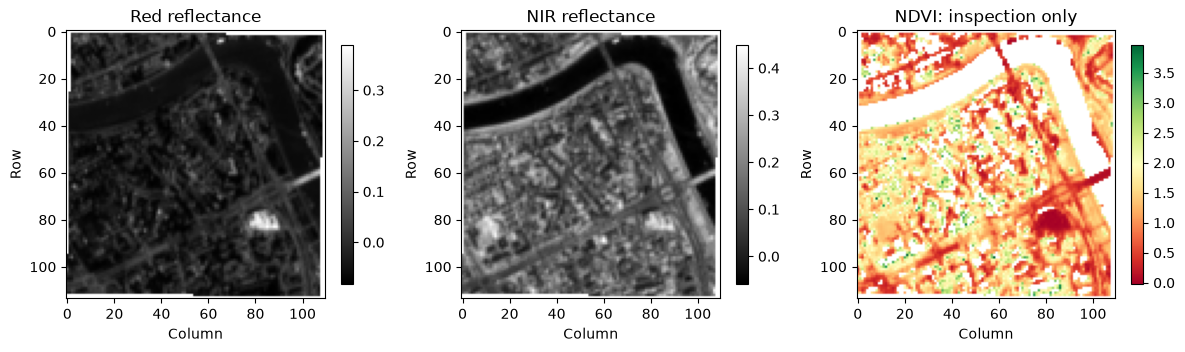

In [ ]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

paths = {}
if DB.is_file():
    with sqlite3.connect(f'{DB.as_uri()}?mode=ro', uri=True) as conn:
        names = {row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        if 'artifact_locations' in names:
            for band, path in conn.execute("""SELECT a.asset_key,l.local_path FROM subset_requests s
                JOIN assets a USING(asset_id) JOIN artifact_locations l ON l.artifact_id=s.latest_artifact_id
                WHERE l.status='available' ORDER BY s.updated_at"""):
                paths[band] = Path(path)
if set(paths) != {'red','nir'} or not all(p.is_file() for p in paths.values()):
    print('Acquire both main-archive AOI subsets first; no download is performed by this cell.')
else:
    arrays = {}
    grids = {}
    for band, path in paths.items():
        with rasterio.open(path) as src:
            grids[band] = (src.crs, src.transform, src.shape)
            arrays[band] = src.read(1, masked=True).astype('float32') * src.scales[0] + src.offsets[0]
            print(band, src.shape, src.crs, 'scale:', src.scales[0], 'offset:', src.offsets[0])
    assert grids['red'] == grids['nir'], 'Choose the same AOI and aligned bands'
    red, nir = arrays['red'], arrays['nir']
    denominator = nir + red
    with np.errstate(divide='ignore', invalid='ignore'):
        ndvi = np.ma.masked_where(denominator <= 0, (nir-red) / denominator)
    fig, axes = plt.subplots(1,3,figsize=(12,4))
    for ax, values, title in zip(axes,[red,nir,ndvi],['Red reflectance','NIR reflectance','NDVI: inspection only']):
        im = ax.imshow(values, cmap='RdYlGn' if title.startswith('NDVI') else 'gray')
        ax.set_title(title); ax.set_xlabel('Column'); ax.set_ylabel('Row')
        fig.colorbar(im,ax=ax,shrink=0.65)
    plt.tight_layout()
    plt.show()


I believe that the super large NDVI color scale comes from pixels where `nir + red` reflectance is close to or below zero. A good method to reduce the color scale would be to apply a lower threshold for the sum of both channels. Example below (sorry for copy paste)

red (114, 110) EPSG:32634 scale: 0.0001 offset: -0.1
nir (114, 110) EPSG:32634 scale: 0.0001 offset: -0.1


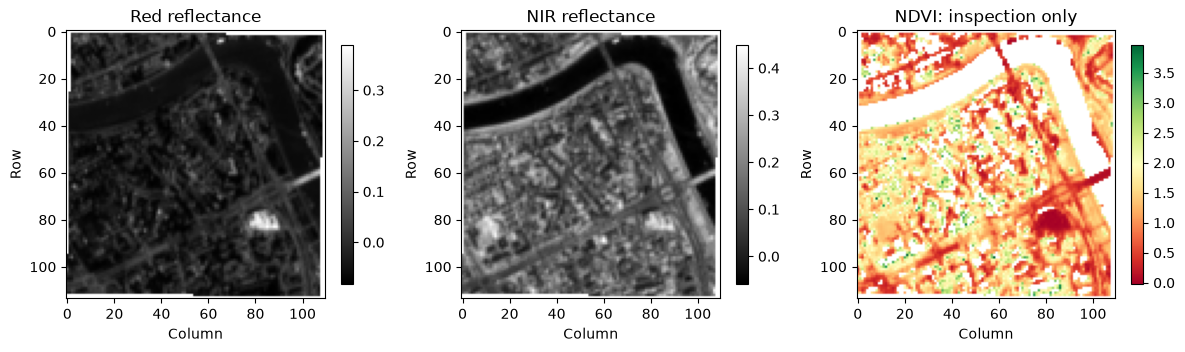

In [6]:
paths = {}
if DB.is_file():
    with sqlite3.connect(f'{DB.as_uri()}?mode=ro', uri=True) as conn:
        names = {row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        if 'artifact_locations' in names:
            for band, path in conn.execute("""SELECT a.asset_key,l.local_path FROM subset_requests s
                JOIN assets a USING(asset_id) JOIN artifact_locations l ON l.artifact_id=s.latest_artifact_id
                WHERE l.status='available' ORDER BY s.updated_at"""):
                paths[band] = Path(path)
if set(paths) != {'red','nir'} or not all(p.is_file() for p in paths.values()):
    print('Acquire both main-archive AOI subsets first; no download is performed by this cell.')
else:
    arrays = {}
    grids = {}
    for band, path in paths.items():
        with rasterio.open(path) as src:
            grids[band] = (src.crs, src.transform, src.shape)
            arrays[band] = src.read(1, masked=True).astype('float32') * src.scales[0] + src.offsets[0]
            print(band, src.shape, src.crs, 'scale:', src.scales[0], 'offset:', src.offsets[0])
    assert grids['red'] == grids['nir'], 'Choose the same AOI and aligned bands'
    red, nir = arrays['red'], arrays['nir']
    denominator = nir + red
    with np.errstate(divide='ignore', invalid='ignore'):
        valid = denominator > 0.05
        ndvi = np.ma.masked_where(~valid, (nir - red) / denominator)
    fig, axes = plt.subplots(1,3,figsize=(12,4))
    for ax, values, title in zip(axes,[red,nir,ndvi],['Red reflectance','NIR reflectance','NDVI: inspection only']):
        im = ax.imshow(values, cmap='RdYlGn' if title.startswith('NDVI') else 'gray')
        ax.set_title(title); ax.set_xlabel('Column'); ax.set_ylabel('Row')
        fig.colorbar(im,ax=ax,shrink=0.65)
    plt.tight_layout()
    plt.show()

## Submission and interpretation

Submit student_schema.sql, your investigation_queries.sql, this notebook with
predictions/SQL results/explanations, and a small report:

```bash
python lab03_cli.py report --config config/krakow_aoi.json > lab03_report.json
```

For each required failure, state: symptom, query, observed rows, diagnosis, recovery,
and post-recovery evidence. A screenshot alone is not a diagnosis. Explain which
claims are protected by database constraints and which require checking bytes,
filesystem state or raster metadata.

Keep state/, data/, and cases/ out of Git. Successful offline checks do not claim
that a live request succeeded. If the provider/network is unavailable, retain that
failure evidence and complete the live acquisition later; no synthetic image is
substituted.

Sources: [Rasterio windowed reading/writing](https://rasterio.readthedocs.io/en/latest/topics/windowed-rw.html)
and [Earth Search metadata](https://github.com/Element84/earth-search/blob/main/README.md).

### Final status

The schema checks passed. Both bands were acquired or reused, the archive was verified, and the report was generated. The failure cases were recovered while preserving the original attempt history.
